In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

In [ ]:
sharelink = "https://drive.google.com/file/d/1WDg8tVaYfriOHGiv0gM7J_Bz9CJZqfw9/view?usp=share_link"
URL = 'https://drive.google.com/uc?export=download&id='+ sharelink.split('/')[-2]
df = pd.read_csv(URL)

In [ ]:
df

,Unnamed: 0,customer_id,time,event_offer_completed,event_offer_received,event_offer_viewed,event_transaction,offer_id,amount,gender,...,gender_M,gender_O,reward,difficulty,duration,offer_type,channel_email,channel_mobile,channel_social,channel_web
0,0,78afa995795e4d85b5d9ceeca43f5fef,0,0,1,0,0,B3,NaN,F,...,0,0,5.0,5.0,7.0,bogo,1.0,1.0,0.0,1.0
1,1,a03223e636434f42ac4c3df47e8bac43,0,0,1,0,0,D1,NaN,NaN,...,0,0,5.0,20.0,10.0,discount,1.0,0.0,0.0,1.0
2,2,e2127556f4f64592b11af22de27a7932,0,0,1,0,0,D4,NaN,M,...,1,0,2.0,10.0,7.0,discount,1.0,1.0,0.0,1.0
3,3,8ec6ce2a7e7949b1bf142def7d0e0586,0,0,1,0,0,D3,NaN,NaN,...,0,0,2.0,10.0,10.0,discount,1.0,1.0,1.0,1.0
4,4,68617ca6246f4fbc85e91a2a49552598,0,0,1,0,0,B2,NaN,NaN,...,0,0,10.0,10.0,5.0,bogo,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306529,306529,b3a1272bc9904337b331bf348c3e8c17,714,0,0,0,1,NaN,1.59,M,...,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
306530,306530,68213b08d99a4ae1b0dcb72aebd9aa35,714,0,0,0,1,NaN,9.53,M,...,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
306531,306531,a00058cf10334a308c68e7631c529907,714,0,0,0,1,NaN,3.61,F,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
306532,306532,76ddbd6576844afe811f1a3c0fbb5bec,714,0,0,0,1,NaN,3.53,M,...,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.describe(include='all').transpose().style.background_gradient(cmap='GnBu')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,306534.000000,nan,nan,nan,153266.500000,88488.888045,0.000000,76633.250000,153266.500000,229899.750000,306533.000000
customer_id,306534,17000,94de646f7b6041228ca7dec82adb97d2,51,nan,nan,nan,nan,nan,nan,nan
time,306534.000000,nan,nan,nan,366.382940,200.326314,0.000000,186.000000,408.000000,528.000000,714.000000
event_offer_completed,306534.000000,nan,nan,nan,0.109544,0.312321,0.000000,0.000000,0.000000,0.000000,1.000000
event_offer_received,306534.000000,nan,nan,nan,0.248837,0.432340,0.000000,0.000000,0.000000,0.000000,1.000000
event_offer_viewed,306534.000000,nan,nan,nan,0.188315,0.390964,0.000000,0.000000,0.000000,0.000000,1.000000
event_transaction,306534.000000,nan,nan,nan,0.453304,0.497815,0.000000,0.000000,0.000000,1.000000,1.000000
offer_id,167581,10,D3,20241,nan,nan,nan,nan,nan,nan,nan
amount,138953.000000,nan,nan,nan,12.777356,30.250529,0.050000,2.780000,8.890000,18.070000,1062.280000
gender,272762,3,M,155690,nan,nan,nan,nan,nan,nan,nan


Drop some useless columns

In [ ]:
df = df.drop(['customer_id','Unnamed: 0','gender_F','gender_M','gender_O'],axis = 1)

PreProcessing

1. Categorical features: Impute them use mode

In [ ]:
df['offer_id'].fillna(value='D3',inplace=True)
df['gender'].fillna(value='M',inplace=True)
df['became_member_on'].fillna(value='2017/12/7',inplace=True)
df['offer_type'].fillna(value='bogo',inplace=True)
df['channel_email'].fillna(value='1.0',inplace=True)
df['channel_mobile'].fillna(value='1.0',inplace=True)
df['channel_social'].fillna(value='1.0',inplace=True)
df['channel_web'].fillna(value='1.0',inplace=True)
df[['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','became_member_on','valid','offer_type','channel_email','channel_mobile','channel_social','channel_web']] = df[['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','became_member_on','valid','offer_type','channel_email','channel_mobile','channel_social','channel_web']].astype(str)

In [ ]:
Categorical = df[['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','became_member_on','valid','channel_email','channel_mobile','channel_social','channel_web']]

2. Numerical features: Impute them use Median

In [ ]:
Numerical = df.drop(['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','became_member_on','valid','offer_type','channel_email','channel_mobile','channel_social','channel_web'],axis = 1)

In [ ]:
for i in Numerical:
  Numerical[i].fillna(Numerical[i].median(), inplace=True)

In [ ]:
df[['time','amount','age','income','reward','difficulty','duration']] = Numerical

3. After checking, no missing values

In [ ]:
Categorical.describe().transpose()

,count,unique,top,freq
event_offer_completed,306534,2,0,272955
event_offer_received,306534,2,0,230257
event_offer_viewed,306534,2,0,248809
event_transaction,306534,2,0,167581
offer_id,306534,10,D3,159194
gender,306534,3,M,189462
became_member_on,306534,1716,2017/12/7,754
valid,306534,2,1,272762
channel_email,306534,1,1.0,306534
channel_mobile,306534,2,1.0,292783


In [ ]:
Numerical.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
time,306534.0,366.382940,200.326314,0.00,186.00,408.00,528.00,714.00
amount,306534.0,10.652153,20.458715,0.05,8.89,8.89,8.89,1062.28
age,306534.0,60.909367,26.032030,18.00,43.00,57.00,72.00,118.00
income,306534.0,64079.524620,20052.720460,30000.00,50000.00,62000.00,75000.00,120000.00
reward,306534.0,4.682867,2.510884,0.00,3.00,5.00,5.00,10.00
difficulty,306534.0,8.824822,3.883475,0.00,7.00,10.00,10.00,20.00
duration,306534.0,6.787192,1.591272,3.00,7.00,7.00,7.00,10.00


Univariate Analysis

1. Numerical Varibales (Box plot & Histogram)

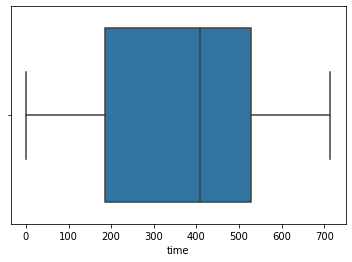

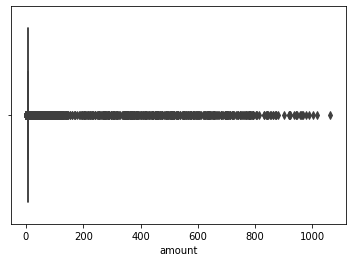

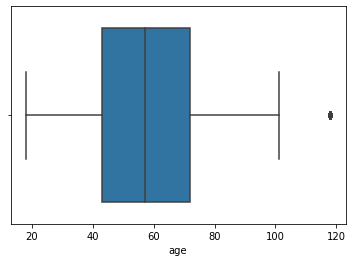

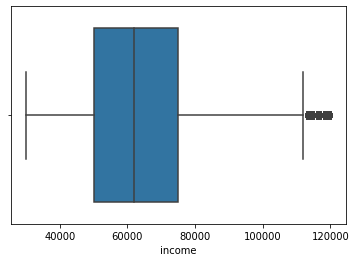

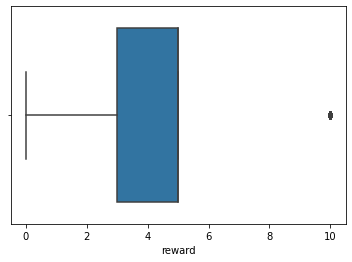

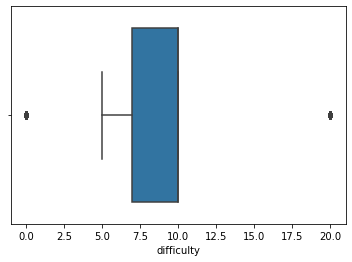

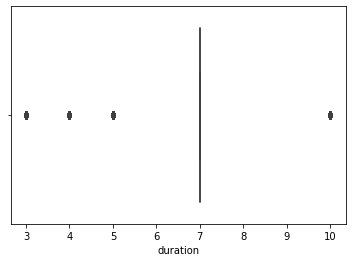

In [ ]:
titles = Numerical[:-1].values.tolist()
plt.figure()
for i, variable in enumerate(Numerical[:-1]):
    sns.boxplot(x=Numerical[variable],data=Numerical,orient="v")
    plt.show()

<Figure size 864x576 with 0 Axes>

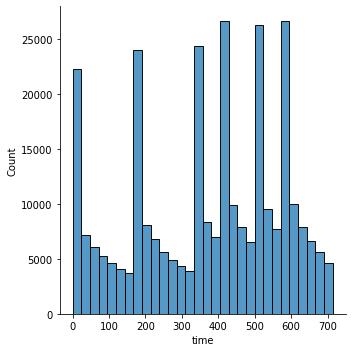

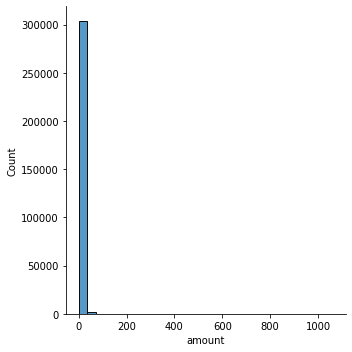

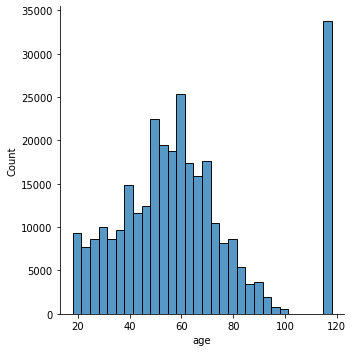

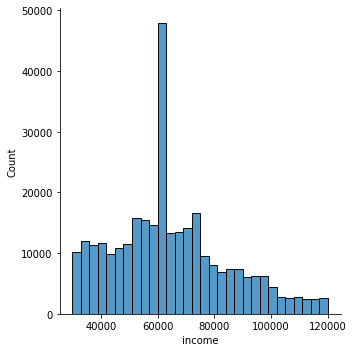

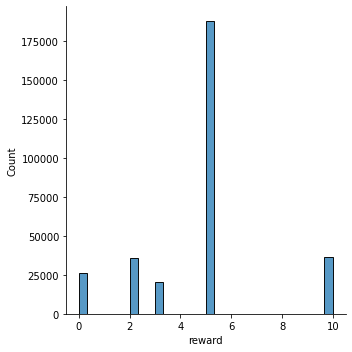

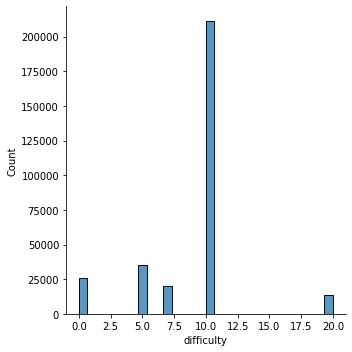

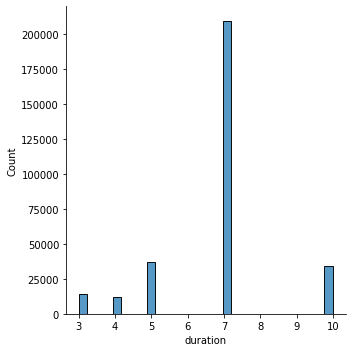

In [ ]:
titles = Numerical[:-1].values.tolist()
plt.figure(figsize=(12,8))
for i, variable in enumerate(Numerical[:-1]):
    sns.displot(x=Numerical[variable],data=Numerical,bins=30)
    plt.show()

2. Categorical features: Bar chart

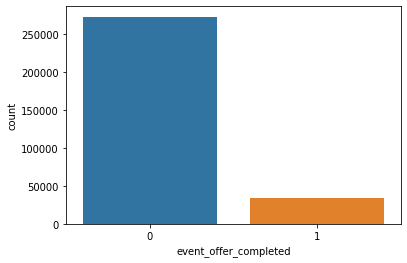

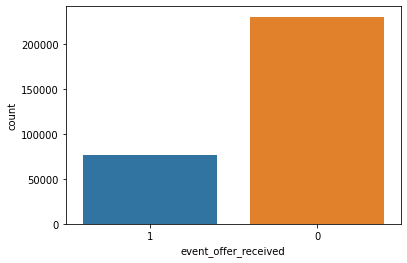

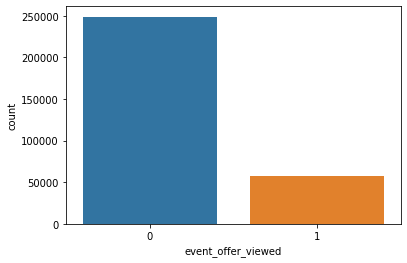

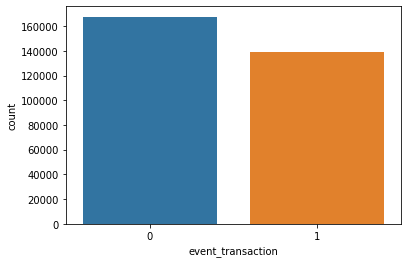

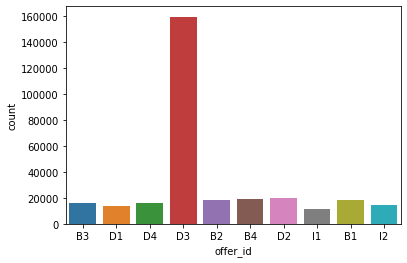

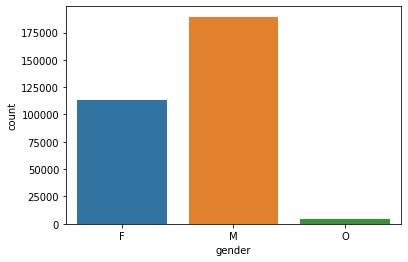

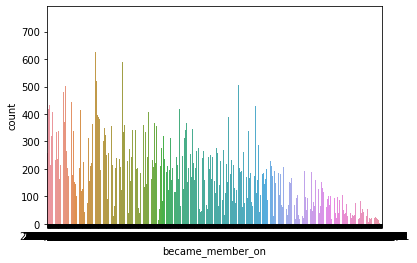

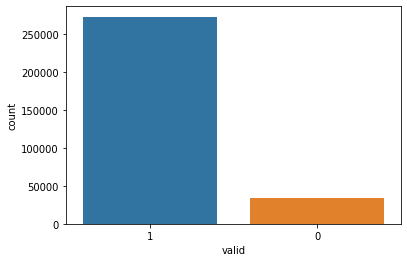

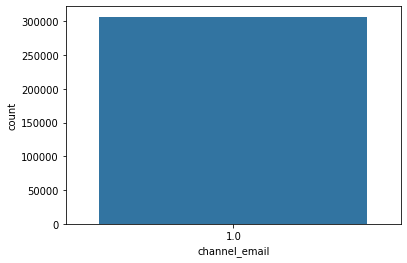

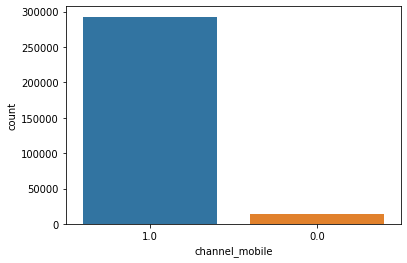

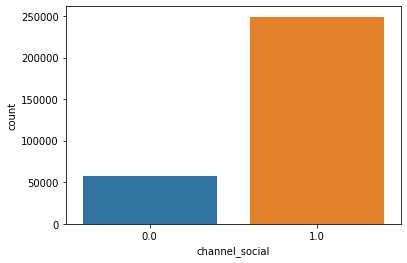

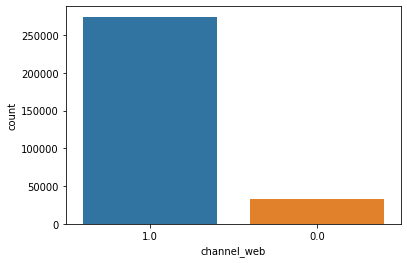

In [ ]:
titles = Categorical[:-1].values.tolist()
for i, variable in enumerate(Categorical[:-1]):

    sns.countplot(x=df[variable],data=df)
    plt.show()

Bivariate Analysis

1. Numerical Features V.S Target

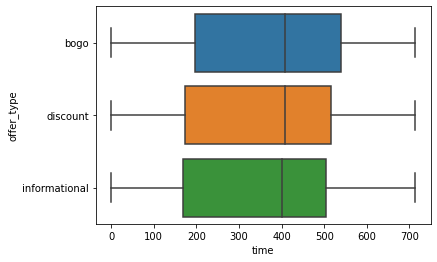

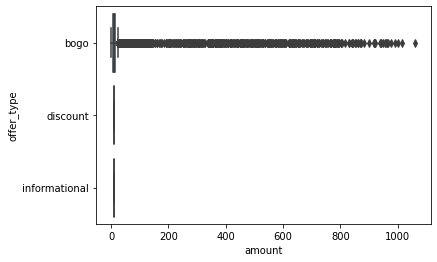

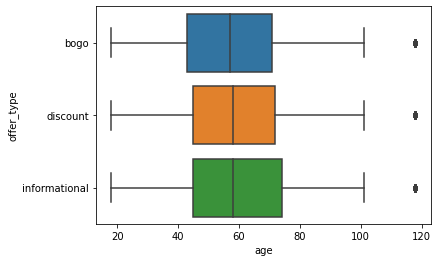

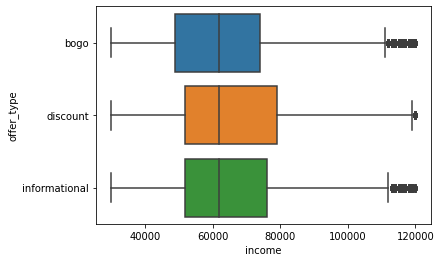

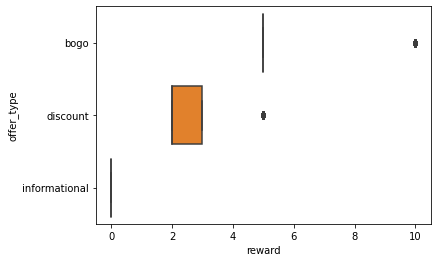

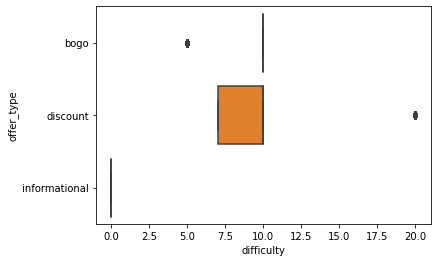

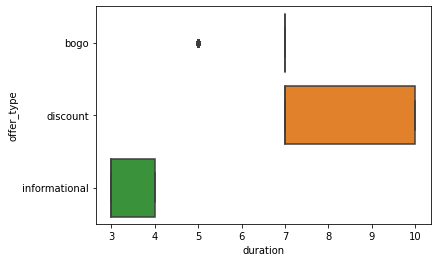

In [ ]:
titles = Numerical[:-1].values.tolist()
for i, variable in enumerate(Numerical[:-1]):
  sns.boxplot(x=df[variable], y=df['offer_type'])
  plt.show()

2. Categorical Features V.S Target

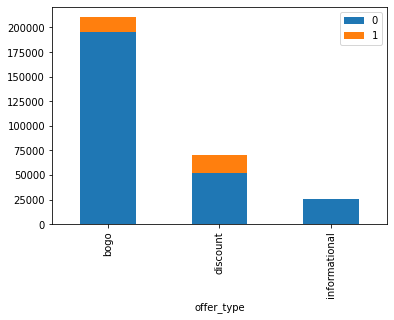

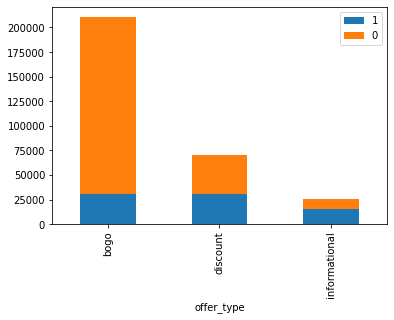

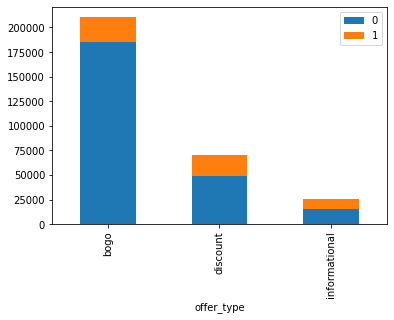

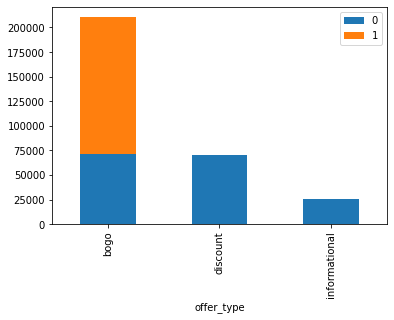

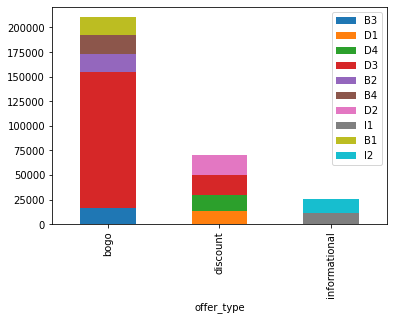

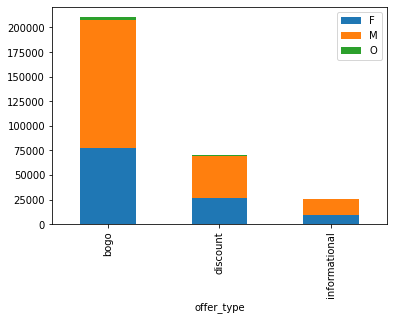

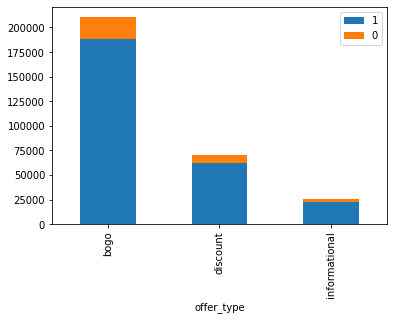

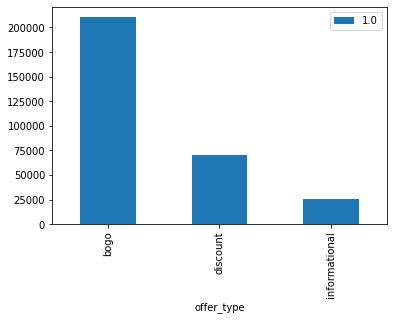

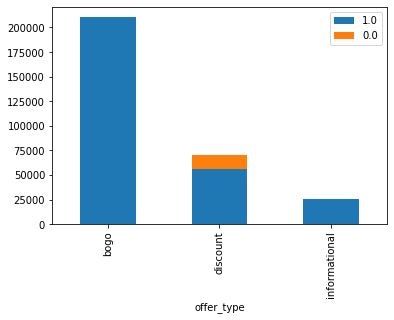

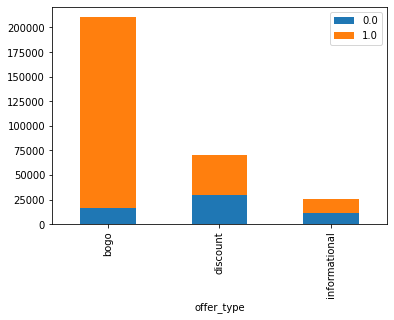

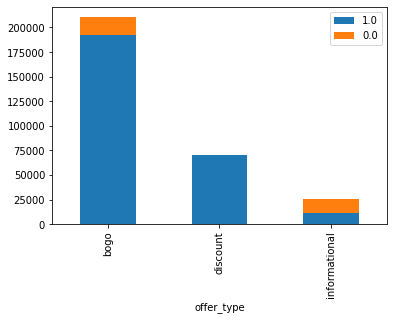

In [ ]:
Categorical11 = df[['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','valid','channel_email','channel_mobile','channel_social','channel_web']]
def aggregate(rows,columns,df):
    column_keys = df[columns].unique()
    row_keys = df[rows].unique()
    agg = { key : [ len(df[(df[rows]==value) & (df[columns]==key)]) for value in row_keys]
            for key in column_keys }
    aggdf = pd.DataFrame(agg,index = row_keys)
    aggdf.index.rename(rows,inplace=True)
    return aggdf

titles = Categorical11[:-1].values.tolist()
for i, variable in enumerate(Categorical11[:-1]):
  aggregate('offer_type',variable,df).plot(kind='bar',stacked=True)
  plt.show()

Multivariate Analysis

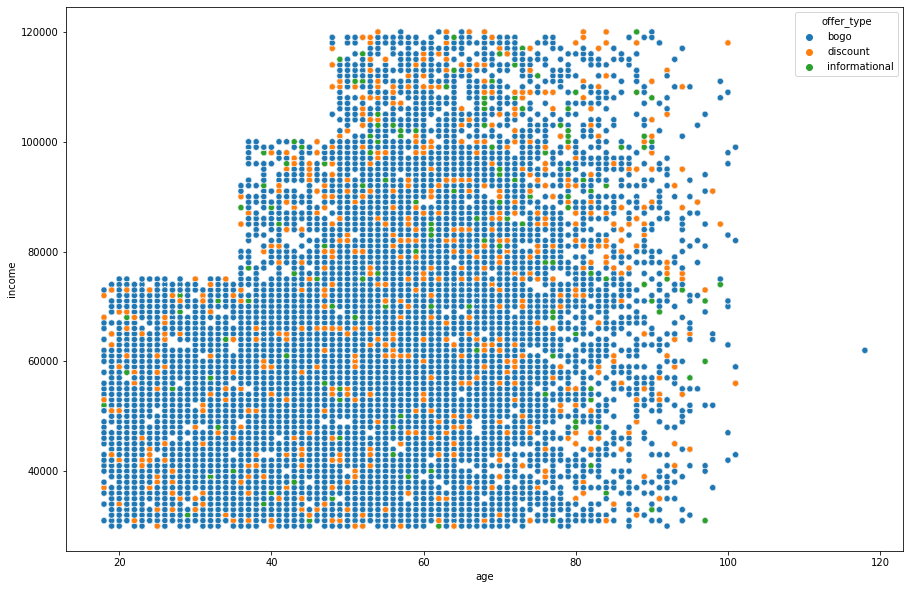

In [ ]:
plt.figure(figsize=(15, 10))
sns.scatterplot(x=df['age'], y=df['income'],hue=df['offer_type'])
plt.show()

Lable Encoding and change it into Categorical type

In [ ]:
from sklearn import preprocessing
le = preprocessing.LabelEncoder()

for i in Categorical:
  df[i] = le.fit_transform(df[i])
  df[i] = df[i].astype(str)

df['offer_type'] = le.fit_transform(df['offer_type'])
df['offer_type'] = df['offer_type'].astype(str)

Feature Selection

In [ ]:
CategoricalFeature = df[['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','became_member_on','valid','channel_email','channel_mobile','channel_social','channel_web']]

In [ ]:
NumericalFeature = df.drop(['event_offer_completed','event_offer_received','event_offer_viewed','event_transaction'
,'offer_id','gender','became_member_on','valid','offer_type','channel_email','channel_mobile','channel_social','channel_web'],axis = 1)

In [ ]:
Target = df['offer_type']

1. Categorical VS Categorical

In [ ]:
# Chi-square test
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
Selector = SelectKBest(chi2,k = 7)
fit = Selector.fit(CategoricalFeature,Target)
pvalues = fit.pvalues_
aa = pd.DataFrame([pvalues],index=['p-value'],columns = CategoricalFeature.columns).T
aa

,p-value
event_offer_completed,0.000000
event_offer_received,0.000000
event_offer_viewed,0.000000
event_transaction,0.000000
offer_id,0.000000
gender,0.000024
became_member_on,0.000000
valid,0.001197
channel_email,NaN
channel_mobile,0.000000


2. Numerical VS Categorical

In [ ]:
# ANOVA


from sklearn.feature_selection import f_classif

F_score, p_value = f_classif(NumericalFeature, Target)

aa = pd.DataFrame([F_score,p_value], index=['F-score','p-value'], columns=NumericalFeature.columns).T
aa

,F-score,p-value
time,328.488473,3.104064e-143
amount,519.946897,3.733305e-226
age,148.711338,2.797687e-65
income,546.739235,9.477185e-238
reward,199021.719772,0.000000e+00
difficulty,167858.530966,0.000000e+00
duration,261940.491745,0.000000e+00


Summary: channel_email need to be exclueded.

Export new dataset

In [ ]:
# df.drop('channel_email',axis=1)

,time,event_offer_completed,event_offer_received,event_offer_viewed,event_transaction,offer_id,amount,gender,age,became_member_on,income,valid,reward,difficulty,duration,offer_type,channel_mobile,channel_social,channel_web
0,0,0,1,0,0,2,8.89,0,75,1386,100000.0,1,5.0,5.0,7.0,0,1,0,1
1,0,0,1,0,0,4,8.89,1,118,1473,62000.0,0,5.0,20.0,10.0,1,0,0,1
2,0,0,1,0,0,7,8.89,1,68,1617,70000.0,1,2.0,10.0,7.0,1,1,0,1
3,0,0,1,0,0,6,8.89,1,118,1496,62000.0,0,2.0,10.0,10.0,1,1,1,1
4,0,0,1,0,0,1,8.89,1,118,1186,62000.0,0,10.0,10.0,5.0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306529,714,0,0,0,1,6,1.59,1,66,1509,47000.0,1,5.0,10.0,7.0,0,1,1,1
306530,714,0,0,0,1,6,9.53,1,52,1627,62000.0,1,5.0,10.0,7.0,0,1,1,1
306531,714,0,0,0,1,6,3.61,0,63,119,52000.0,1,5.0,10.0,7.0,0,1,1,1
306532,714,0,0,0,1,6,3.53,1,57,1082,40000.0,1,5.0,10.0,7.0,0,1,1,1


In [ ]:
# df.to_csv('starbucksnew.csv')

Data modelling

In [ ]:
# Load csv file
sharelink = "https://drive.google.com/file/d/12iyQp5x41j-9zZQuE-iCfPxob5XzuqYg/view?usp=share_link"
URL = 'https://drive.google.com/uc?export=download&id='+ sharelink.split('/')[-2]
df = pd.read_csv(URL)
df

,time,event_offer_completed,event_offer_received,event_offer_viewed,event_transaction,offer_id,amount,gender,age,became_member_on,income,valid,reward,difficulty,duration,offer_type,channel_email,channel_mobile,channel_social,channel_web
0,0,0,1,0,0,2,8.89,0,75,1386,100000,1,5,5,7,0,0,1,0,1
1,0,0,1,0,0,4,8.89,1,118,1473,62000,0,5,20,10,1,0,0,0,1
2,0,0,1,0,0,7,8.89,1,68,1617,70000,1,2,10,7,1,0,1,0,1
3,0,0,1,0,0,6,8.89,1,118,1496,62000,0,2,10,10,1,0,1,1,1
4,0,0,1,0,0,1,8.89,1,118,1186,62000,0,10,10,5,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306529,714,0,0,0,1,6,1.59,1,66,1509,47000,1,5,10,7,0,0,1,1,1
306530,714,0,0,0,1,6,9.53,1,52,1627,62000,1,5,10,7,0,0,1,1,1
306531,714,0,0,0,1,6,3.61,0,63,119,52000,1,5,10,7,0,0,1,1,1
306532,714,0,0,0,1,6,3.53,1,57,1082,40000,1,5,10,7,0,0,1,1,1


In [ ]:
# To get a glimpse of the data structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306534 entries, 0 to 306533
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   time                   306534 non-null  int64  
 1   event_offer_completed  306534 non-null  int64  
 2   event_offer_received   306534 non-null  int64  
 3   event_offer_viewed     306534 non-null  int64  
 4   event_transaction      306534 non-null  int64  
 5   offer_id               306534 non-null  int64  
 6   amount                 306534 non-null  float64
 7   gender                 306534 non-null  int64  
 8   age                    306534 non-null  int64  
 9   became_member_on       306534 non-null  int64  
 10  income                 306534 non-null  int64  
 11  valid                  306534 non-null  int64  
 12  reward                 306534 non-null  int64  
 13  difficulty             306534 non-null  int64  
 14  duration               306534 non-nu

In [ ]:
# Drop channel_email based on ANOVA
dfnew = df.drop('channel_email',axis=1)
dfnew

,time,event_offer_completed,event_offer_received,event_offer_viewed,event_transaction,offer_id,amount,gender,age,became_member_on,income,valid,reward,difficulty,duration,offer_type,channel_mobile,channel_social,channel_web
0,0,0,1,0,0,2,8.89,0,75,1386,100000,1,5,5,7,0,1,0,1
1,0,0,1,0,0,4,8.89,1,118,1473,62000,0,5,20,10,1,0,0,1
2,0,0,1,0,0,7,8.89,1,68,1617,70000,1,2,10,7,1,1,0,1
3,0,0,1,0,0,6,8.89,1,118,1496,62000,0,2,10,10,1,1,1,1
4,0,0,1,0,0,1,8.89,1,118,1186,62000,0,10,10,5,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306529,714,0,0,0,1,6,1.59,1,66,1509,47000,1,5,10,7,0,1,1,1
306530,714,0,0,0,1,6,9.53,1,52,1627,62000,1,5,10,7,0,1,1,1
306531,714,0,0,0,1,6,3.61,0,63,119,52000,1,5,10,7,0,1,1,1
306532,714,0,0,0,1,6,3.53,1,57,1082,40000,1,5,10,7,0,1,1,1


In [ ]:
# Drop target variable
X = dfnew.drop('offer_type', axis=1)
X.shape

(306534, 18)

In [ ]:
X.head()

,time,event_offer_completed,event_offer_received,event_offer_viewed,event_transaction,offer_id,amount,gender,age,became_member_on,income,valid,reward,difficulty,duration,channel_mobile,channel_social,channel_web
0,0,0,1,0,0,2,8.89,0,75,1386,100000,1,5,5,7,1,0,1
1,0,0,1,0,0,4,8.89,1,118,1473,62000,0,5,20,10,0,0,1
2,0,0,1,0,0,7,8.89,1,68,1617,70000,1,2,10,7,1,0,1
3,0,0,1,0,0,6,8.89,1,118,1496,62000,0,2,10,10,1,1,1
4,0,0,1,0,0,1,8.89,1,118,1186,62000,0,10,10,5,1,1,1


In [ ]:
# Assign target variable
y = dfnew['offer_type']
y.shape

(306534,)

In [ ]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: offer_type, dtype: int64

In [ ]:
# Split data for training and testing
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state = 42, test_size=0.2)

Logistic Regression

In [ ]:
# Training model
clf = LogisticRegression()
clf.fit(Xtrain, ytrain)

LogisticRegression()

In [ ]:
# Prediction
pred = clf.predict(Xtest)
pred

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
# Evaluation
accuracy = accuracy_score(ytest, pred)
print('Accuracy: ', accuracy)

Accuracy:  0.6851909243642651


In [ ]:
print(classification_report(ytest,pred))

              precision    recall  f1-score   support

           0       0.69      0.99      0.81     42263
           1       0.27      0.02      0.03     13832
           2       0.00      0.00      0.00      5212

    accuracy                           0.69     61307
   macro avg       0.32      0.34      0.28     61307
weighted avg       0.54      0.69      0.57     61307



XGBoost

In [ ]:
# Training model
xgbclf = xgb.XGBClassifier()
xgbclf.fit(Xtrain, ytrain)

XGBClassifier(objective='multi:softprob')

In [ ]:
# Prediction
pred = xgbclf.predict(Xtest)
pred

array([0, 1, 0, ..., 0, 0, 0])

In [ ]:
# Evaluation
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(ytest, pred)
print('Accuracy: ', accuracy)

Accuracy:  1.0


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(ytest,pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42263
           1       1.00      1.00      1.00     13832
           2       1.00      1.00      1.00      5212

    accuracy                           1.00     61307
   macro avg       1.00      1.00      1.00     61307
weighted avg       1.00      1.00      1.00     61307



Random Forest

In [ ]:
# Train model
rfclf = RandomForestClassifier()
rfclf.fit(Xtrain, ytrain)

RandomForestClassifier()

In [ ]:
# Prediction
pred = rfclf.predict(Xtest)
pred

array([0, 1, 0, ..., 0, 0, 0])

In [ ]:
# Evaluation
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(ytest, pred)
print('Accuracy: ', accuracy)

Accuracy:  1.0


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(ytest,pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42263
           1       1.00      1.00      1.00     13832
           2       1.00      1.00      1.00      5212

    accuracy                           1.00     61307
   macro avg       1.00      1.00      1.00     61307
weighted avg       1.00      1.00      1.00     61307



Hyperparameter tuning

In [ ]:
# Number of trees in random forest
n_estimators = [int(x) for x in np.linspace(start = 50, stop = 500, num = 4)]
# Number of features to consider at every split
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 4)]
max_depth.append(None)
# Method of selecting samples for training each tree
bootstrap = [True, False]# Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'bootstrap': bootstrap}

print(random_grid)

{'n_estimators': [50, 200, 350, 500], 'max_features': ['auto', 'sqrt'], 'max_depth': [10, 43, 76, 110, None], 'bootstrap': [True, False]}


In [ ]:
# Use the random grid to search for best hyperparameters
from sklearn.model_selection import RandomizedSearchCV
# First create the base model to tune
rf = RandomForestClassifier()
# Random search of parameters, using 3 fold cross validation, 
# search across 100 different combinations, and use all available cores
rf_random = RandomizedSearchCV(estimator = rf, param_distributions = random_grid, n_iter = 10, cv = 3, verbose=10, random_state=42, n_jobs = -1)
# Fit the random search model
rf_random.fit(Xtrain, ytrain)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(), n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [10, 43, 76, 110, None],
                                        'max_features': ['auto', 'sqrt'],
                                        'n_estimators': [50, 200, 350, 500]},
                   random_state=42, verbose=10)

In [ ]:
pred2 = rf_random.predict(Xtest)
pred2

array([0, 1, 0, ..., 0, 0, 0])

In [ ]:
accuracy2 = accuracy_score(ytest, pred2)
print('Accuracy of tuned model: ', accuracy2)

Accuracy of tuned model:  1.0


In [ ]:
print(classification_report(ytest,pred2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42263
           1       1.00      1.00      1.00     13832
           2       1.00      1.00      1.00      5212

    accuracy                           1.00     61307
   macro avg       1.00      1.00      1.00     61307
weighted avg       1.00      1.00      1.00     61307

